<a href="https://colab.research.google.com/github/sergeydorof/neural_networks_labs/blob/main/lab2/nn_lab2_b.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
from sklearn.preprocessing import StandardScaler

def prepare_mlp_data(df, L_days=7, target_col='target_temp_next_week', test_size=0.15, val_size=0.15):
    """
    Готовит датасет для MLP: создает лаги, удаляет NaN,
    проводит хронологическое деление и масштабирует только не-циклические признаки.
    """
    window_size = int(L_days * 24)

    feature_cols = [col for col in df.columns if col != target_col]

    # 1. Сбор лагов в словарь
    lagged_dict = {}
    for col in feature_cols:
        for lag in range(1, window_size + 1):
            lagged_dict[f"{col}_t-{lag}"] = df[col].shift(lag)

    df_lagged = pd.DataFrame(lagged_dict, index=df.index)
    df_lagged[target_col] = df[target_col]

    # 2. Удаление пропусков
    df_lagged = df_lagged.dropna().reset_index(drop=True)

    # 3. Разделение на X и y
    X = df_lagged.drop(columns=[target_col])
    y = df_lagged[target_col]

    # 4. Хронологическое деление на выборки
    n = len(df_lagged)
    train_idx = int(n * (1 - test_size - val_size))
    val_idx = int(n * (1 - test_size))

    X_train, y_train = X.iloc[:train_idx], y.iloc[:train_idx]
    X_val, y_val = X.iloc[train_idx:val_idx], y.iloc[train_idx:val_idx]
    X_test, y_test = X.iloc[val_idx:], y.iloc[val_idx:]

    # 5. Масштабирование признаков (исключая синусы и косинусы)
    scale_cols = [col for col in X.columns if 'sin' not in col and 'cos' not in col]

    scaler_x = StandardScaler()
    X_train_scaled = X_train.copy()
    X_val_scaled = X_val.copy()
    X_test_scaled = X_test.copy()

    X_train_scaled[scale_cols] = scaler_x.fit_transform(X_train[scale_cols])
    X_val_scaled[scale_cols] = scaler_x.transform(X_val[scale_cols])
    X_test_scaled[scale_cols] = scaler_x.transform(X_test[scale_cols])

    # Масштабирование таргета
    scaler_y = StandardScaler()
    y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
    y_val_scaled = scaler_y.transform(y_val.values.reshape(-1, 1)).ravel()
    y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).ravel()

    return (X_train_scaled, X_val_scaled, X_test_scaled,
            y_train_scaled, y_val_scaled, y_test_scaled,
            scaler_x, scaler_y)

In [2]:
import random
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Вызывайте эту функцию перед созданием модели и началом обучения:
set_seed(42)

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from IPython.display import clear_output

def train_and_evaluate(model, train_loader, val_loader, optimizer_type='adam', lr=0.001, epochs=50, patience=5):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)

    # Выбор оптимизатора
    if optimizer_type.lower() == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr)
    elif optimizer_type.lower() == 'sgd':
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    else:
        raise ValueError("Unsupported optimizer type. Use 'adam' or 'sgd'.")

    # Планировщик обучения (снижает LR, если validation loss перестает улучшаться)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    best_val_loss = float('inf')
    patience_counter = 0
    best_weights = None

    for epoch in range(epochs):
        # --- Обучение ---
        model.train()
        train_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * X_batch.size(0)

        train_loss /= len(train_loader.dataset)

        # --- Валидация ---
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                predictions = model(X_batch)
                loss = criterion(predictions, y_batch)
                val_loss += loss.item() * X_batch.size(0)

        val_loss /= len(val_loader.dataset)

        # Шаг планировщика
        scheduler.step(val_loss)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # --- Динамическая отрисовка графика ---
        clear_output(wait=True)
        plt.figure(figsize=(10, 4))
        plt.plot(train_losses, label='Train MSE')
        plt.plot(val_losses, label='Val MSE')
        plt.title(f'Optimizer: {optimizer_type.upper()} | Epoch {epoch+1}/{epochs}')
        plt.xlabel('Эпоха')
        plt.ylabel('MSE Loss')
        plt.legend()
        plt.grid(True)
        plt.show()

        print(f"Эпоха {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        # --- Early Stopping ---
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            best_weights = model.state_dict().copy()
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Ранняя остановка сработала на эпохе {epoch+1}")
                break

    # Загружаем лучшие веса перед выходом
    if best_weights is not None:
        model.load_state_dict(best_weights)

    return train_losses, val_losses

In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_and_plot_model(model, data_loader, scaler_y, title="Model Evaluation", limit = 500):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    model.eval()

    preds = []
    trues = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            outputs = model(X_batch)
            preds.append(outputs.cpu().numpy())
            trues.append(y_batch.numpy())

    preds = np.concatenate(preds, axis=0)
    trues = np.concatenate(trues, axis=0)

    preds_orig = scaler_y.inverse_transform(preds)
    trues_orig = scaler_y.inverse_transform(trues)

    # Находим индексы без NaN как в истинных значениях, так и в предсказаниях
    non_nan_mask = ~np.isnan(trues_orig).any(axis=1) & ~np.isnan(preds_orig).any(axis=1)

    preds_clean = preds_orig[non_nan_mask]
    trues_clean = trues_orig[non_nan_mask]

    mse = mean_squared_error(trues_clean, preds_clean)
    mae = mean_absolute_error(trues_clean, preds_clean)
    r2 = r2_score(trues_clean, preds_clean)

    print(f"=== Метрики качества: {title} ===")
    print(f"MSE : {mse:.4f}")
    print(f"MAE : {mae:.4f} °C")
    print(f"R²  : {r2:.4f}")
    print("================================")

    plt.figure(figsize=(14, 5))
    plt.plot(trues_clean[:limit], label='Истинная температура (True)', color='#1f77b4', alpha=0.9, linewidth=1.5)
    plt.plot(preds_clean[:limit], label='Прогноз модели (Pred)', color='#ff7f0e', linestyle='--', alpha=0.9, linewidth=1.5)
    plt.title(f'Сравнение прогноза и факта — {title}', fontsize=12)
    plt.xlabel('Шаги времени (часы)', fontsize=10)
    plt.ylabel('Температура (°C)', fontsize=10)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return mse, mae, r2, preds_clean, trues_clean

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

def prepare_rnn_data(df, L_days=7, target_col='target_temp_next_week', test_size=0.15, val_size=0.15):
    """
    Готовит 3D-тензоры для рекуррентных моделей (RNN/LSTM/GRU):
    - Создает скользящие окна длиной L_days * 24
    - Масштабирует признаки (кроме sin/cos) и таргет по обучающей выборке
    - Делит на выборки хронологически с сохранением контекста на стыках
    """
    window_size = L_days * 24
    feature_cols = [col for col in df.columns if col != target_col]

    X_raw = df[feature_cols].copy()
    y_raw = df[target_col].copy()

    n = len(df)
    train_end = int(n * (1 - test_size - val_size))
    val_end = int(n * (1 - test_size))

    # 1. Масштабирование признаков (fit строго на train)
    scale_cols = [col for col in feature_cols if 'sin' not in col and 'cos' not in col]
    scaler_x = StandardScaler()
    scaler_x.fit(X_raw.iloc[:train_end][scale_cols])

    X_scaled = X_raw.copy()
    X_scaled[scale_cols] = scaler_x.transform(X_raw[scale_cols])

    # 2. Масштабирование таргета (fit строго на train)
    scaler_y = StandardScaler()
    scaler_y.fit(y_raw.iloc[:train_end].values.reshape(-1, 1))

    y_scaled_vals = scaler_y.transform(y_raw.values.reshape(-1, 1)).ravel()
    y_scaled = pd.Series(y_scaled_vals, index=y_raw.index)

    # 3. Функция нарезки на последовательности (скользящее окно)
    def create_sequences(X_data, y_data, start_idx, end_idx):
        X_seq, y_seq = [], []
        # Начинаем с max(window_size, start_idx), чтобы у первого элемента было достаточно истории
        for i in range(max(window_size, start_idx), end_idx):
            X_seq.append(X_data[i - window_size : i])   # История за последние L дней
            y_seq.append(y_data[i])                     # Целевое значение в момент i
        return np.array(X_seq), np.array(y_seq)

    # Нарезаем выборки
    # Для train: от window_size до train_end
    X_train, y_train = create_sequences(X_scaled.values, y_scaled.values, window_size, train_end)

    # Для val: от train_end до val_end (история для первых элементов берется из конца train)
    X_val, y_val = create_sequences(X_scaled.values, y_scaled.values, train_end, val_end)

    # Для test: от val_end до конца (история для первых элементов берется из конца val)
    X_test, y_test = create_sequences(X_scaled.values, y_scaled.values, val_end, n)

    return (X_train, X_val, X_test,
            y_train, y_val, y_test,
            scaler_x, scaler_y)

In [6]:
import pandas as pd

data = pd.read_csv('weather.csv', index_col=0)

data

,T,P,U,target_temp_next_day,target_temp_next_week,DD_Ветер,DD_Переменное направление,DD_Штиль,year,hour_sin,hour_cos,day_of_year_sin,day_of_year_cos
0,5.0,768.9,76.0,10.791667,12.095238,1.0,0.0,0.0,2012,0.000000,1.000000,-0.966618,0.256222
1,6.0,768.9,81.0,11.083333,12.101190,1.0,0.0,0.0,2012,0.258819,0.965926,-0.966618,0.256222
2,5.0,769.6,81.0,11.416667,12.107143,1.0,0.0,0.0,2012,0.500000,0.866025,-0.966618,0.256222
3,6.0,769.6,76.0,11.666667,12.101190,1.0,0.0,0.0,2012,0.707107,0.707107,-0.966618,0.256222
4,7.0,768.9,71.0,11.875000,12.089286,1.0,0.0,0.0,2012,0.866025,0.500000,-0.966618,0.256222
...,...,...,...,...,...,...,...,...,...,...,...,...,...
70147,13.5,764.3,79.5,12.083333,12.083333,1.0,0.0,0.0,2020,-0.965926,0.258819,-0.966618,0.256222
70148,13.0,764.3,85.0,11.541667,11.541667,1.0,0.0,0.0,2020,-0.866025,0.500000,-0.966618,0.256222
70149,13.0,764.3,82.0,10.500000,10.500000,1.0,0.0,0.0,2020,-0.707107,0.707107,-0.966618,0.256222
70150,10.0,764.3,88.0,11.000000,11.000000,1.0,0.0,0.0,2020,-0.500000,0.866025,-0.966618,0.256222


In [7]:
data = data.drop(columns=['target_temp_next_day'])

Далее для всех выборок буду использовать окно 7 дней

In [8]:
X_train, X_val, X_test, y_train, y_val, y_test, scaler_x, scaler_y = prepare_mlp_data(data, L_days=7)

In [9]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# 1. Создаем кастомный Dataset для PyTorch
class WeatherDataset(Dataset):
    def __init__(self, X, y):
        # Преобразуем DataFrame в массив numpy с помощью .values
        X_np = X.values if hasattr(X, 'values') else X
        self.X = torch.tensor(X_np, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1) # размерность [N, 1]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Создаем DataLoader'ы
train_dataset = WeatherDataset(X_train, y_train)
val_dataset = WeatherDataset(X_val, y_val)
test_dataset = WeatherDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=1024, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

=== МЕТРИКИ КАЧЕСТВА: СУТОЧНЫЙ СРЕДНИЙ БЕЙЗЛАЙН ===
MSE : 14.9872
MAE : 3.0529 °C
R²  : 0.8472


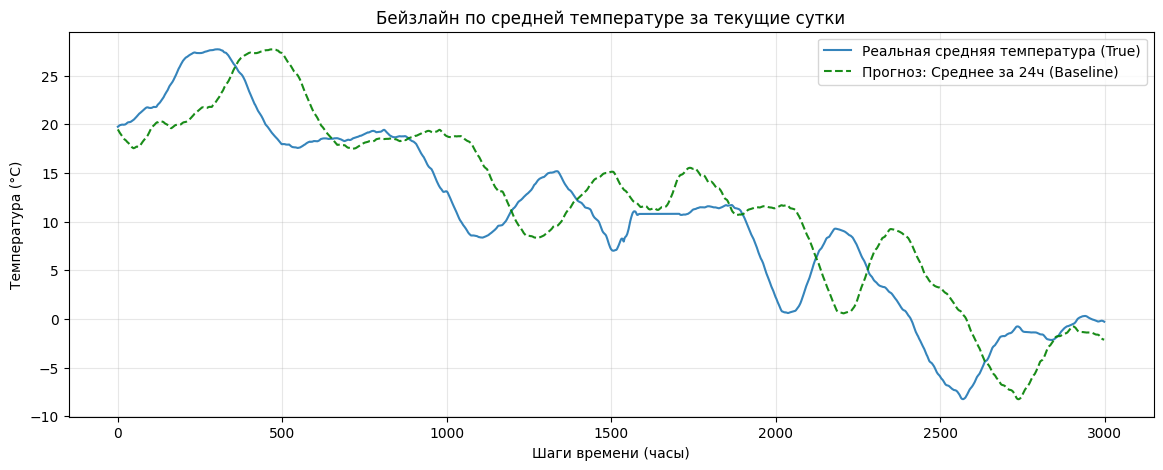

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import torch

# 1. Извлекаем истинные значения таргета из тестового лоадера
trues_scaled = []
with torch.no_grad():
    for _, y_batch in test_loader:
        trues_scaled.append(y_batch.numpy())
trues_scaled = np.concatenate(trues_scaled, axis=0)
trues_orig = scaler_y.inverse_transform(trues_scaled).ravel()

# 2. Нам нужны последние 169 часа лагов температуры: 'T_t-1', 'T_t-2', ..., 'T_t-24'
# Соберем имена этих колонок
temp_lag_cols = [f'T_t-{i}' for i in range(1, 169)]

# Вытаскиваем их из отмасштабированного X_test
lags_scaled = X_test[temp_lag_cols].values

# Возвращаем лаги в исходный масштаб температуры с помощью scaler_y
# lags_orig = scaler_y.inverse_transform(lags_scaled)

cols = list(X_test.columns)
idx = [cols.index(c) for c in temp_lag_cols]

lags_orig = lags_scaled * scaler_x.scale_[idx] + scaler_x.mean_[idx]
preds_mean_orig = lags_orig.mean(axis=1)

# Считаем среднее значение по строкам (средняя температура за последние 24 часа)
# preds_mean_orig = np.mean(lags_orig, axis=1)

# 3. Фильтруем возможные пропуски
mask = ~np.isnan(trues_orig) & ~np.isnan(preds_mean_orig)
trues_clean = trues_orig[mask]
preds_clean = preds_mean_orig[mask]

# 4. Считаем метрики качества для улучшенного бейзлайна
mse_mean_dummy = mean_squared_error(trues_clean, preds_clean)
mae_mean_dummy = mean_absolute_error(trues_clean, preds_clean)
r2_mean_dummy = r2_score(trues_clean, preds_clean)

print("=== МЕТРИКИ КАЧЕСТВА: СУТОЧНЫЙ СРЕДНИЙ БЕЙЗЛАЙН ===")
print(f"MSE : {mse_mean_dummy:.4f}")
print(f"MAE : {mae_mean_dummy:.4f} °C")
print(f"R²  : {r2_mean_dummy:.4f}")
print("===================================================")

# Отобразим фрагмент предсказаний на графике
plt.figure(figsize=(14, 5))
limit = 3000
plt.plot(trues_clean[:limit], label='Реальная средняя температура (True)', color='#1f77b4', alpha=0.9)
plt.plot(preds_clean[:limit], label='Прогноз: Среднее за 24ч (Baseline)', color='green', linestyle='--', alpha=0.9, linewidth=1.5)
plt.title('Бейзлайн по средней температуре за текущие сутки', fontsize=12)
plt.xlabel('Шаги времени (часы)', fontsize=10)
plt.ylabel('Температура (°C)', fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

В одном месте видно расхождение между таргетом и безйлайном: вероятно, это тот отрывок времени, где данные заполнялись искусственно

In [11]:
import torch
import torch.nn as nn

class SimpleWeatherMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(SimpleWeatherMLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)  # Линейный слой с указанным количеством нейронов
        self.activation = nn.ReLU()                  # Функция активации
        self.fc2 = nn.Linear(hidden_dim, 1)          # Выходной слой (1 предсказание)

    def forward(self, x):
        x = self.fc1(x)
        x = self.activation(x)
        x = self.fc2(x)
        return x

Модель 1: MLP с одним слоем

In [12]:
input_dim = X_train.shape[1]
set_seed(42)

model = SimpleWeatherMLP(input_dim=input_dim, hidden_dim=128)

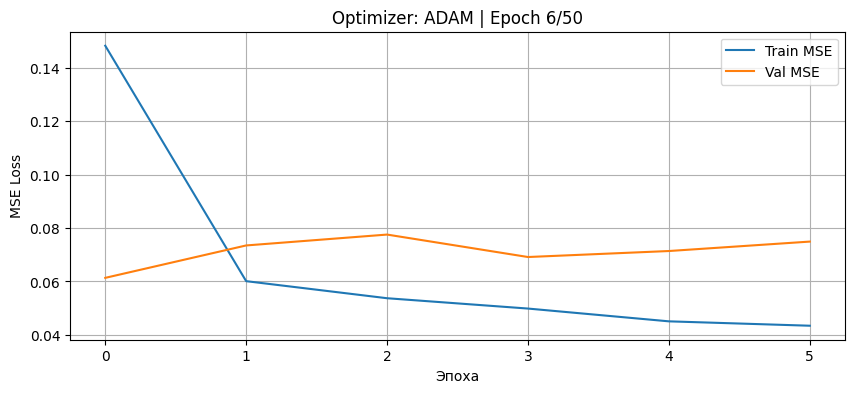

Эпоха 6/50 | Train Loss: 0.0434 | Val Loss: 0.0749
Ранняя остановка сработала на эпохе 6


In [13]:
train_losses_sgd, val_losses_sgd = train_and_evaluate(
    model, train_loader, val_loader, optimizer_type='adam', lr=0.0005
)

=== Метрики качества: MLP ===
MSE : 10.3230
MAE : 2.5138 °C
R²  : 0.9248


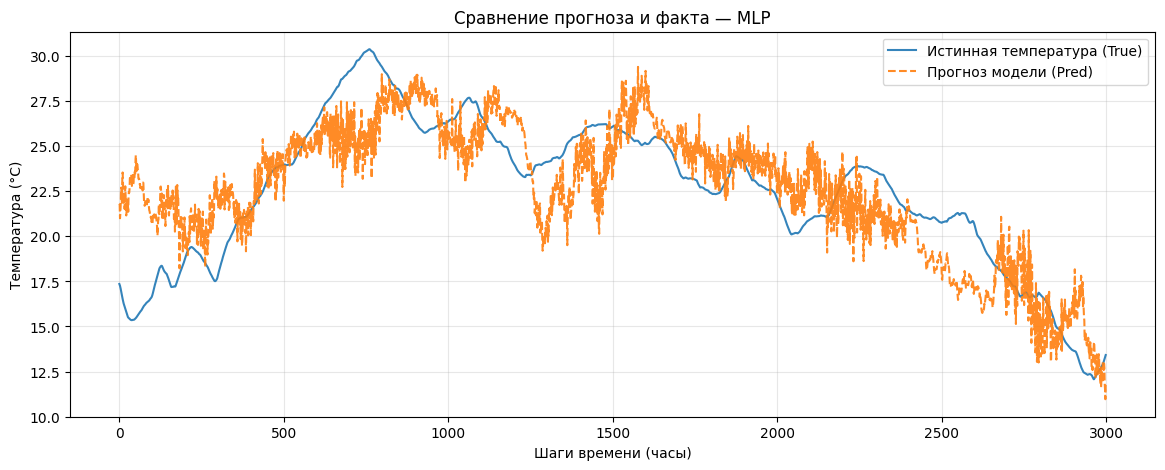

In [15]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model,       # любая ваша модель (MLP или RNN)
    data_loader=val_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="MLP",
    limit=3000
)

Что-то это сильно плохо, буду пробовать 2 слоя

In [16]:
import torch
import torch.nn as nn

class TwoLayerDropoutWeatherMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim1=64, hidden_dim2=32, dropout_rate=0.2):
        super(TwoLayerDropoutWeatherMLP, self).__init__()

        self.fc1 = nn.Linear(input_dim, hidden_dim1)
        self.act1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout_rate)

        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.act2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout_rate)

        self.fc3 = nn.Linear(hidden_dim2, 1)  # Выходной слой

    def forward(self, x):
        x = self.drop1(self.act1(self.fc1(x)))
        x = self.drop2(self.act2(self.fc2(x)))
        x = self.fc3(x)
        return x

# Инициализация модели с Dropout (например, с вероятностью отключения 20%)
set_seed(42)
input_dim = X_train.shape[1]
model_dropout = TwoLayerDropoutWeatherMLP(input_dim=input_dim, hidden_dim1=128, hidden_dim2=64, dropout_rate=0.2)

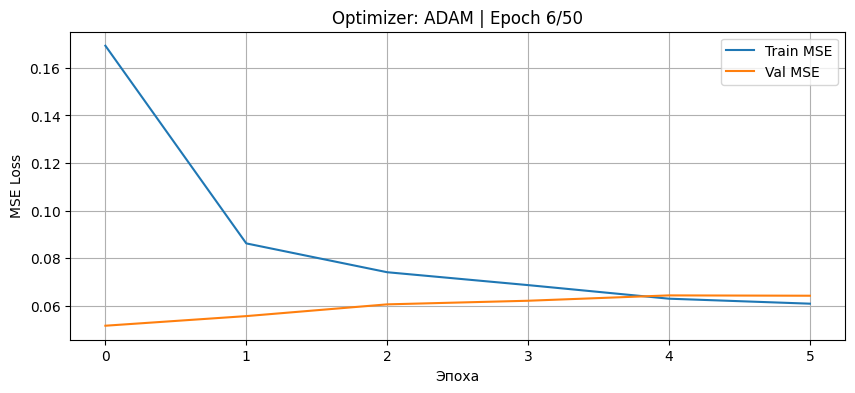

Эпоха 6/50 | Train Loss: 0.0608 | Val Loss: 0.0642
Ранняя остановка сработала на эпохе 6


In [17]:
train_losses_2l, val_losses_2l = train_and_evaluate(
    model_dropout, train_loader, val_loader, optimizer_type='adam', lr=0.001
)

=== Метрики качества: MLP 2L ===
MSE : 8.8408
MAE : 2.3761 °C
R²  : 0.9356


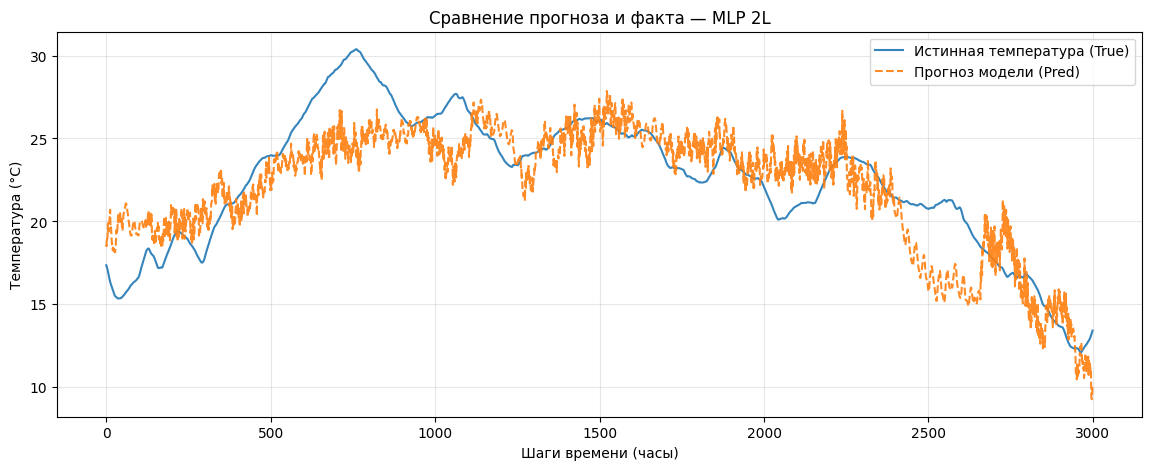

In [18]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model_dropout,       # любая ваша модель (MLP или RNN)
    data_loader=val_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="MLP 2L",
    limit=3000
)

Все еще плохо. Пробую RNN

In [19]:
X_train, X_val, X_test, y_train, y_val, y_test, scaler_x, scaler_y = prepare_rnn_data(data, L_days=7)

In [20]:
import torch
from torch.utils.data import Dataset, DataLoader

class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Создаем датасеты
train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

# Создаем батчи (формат батча X будет [Batch_Size, 168, Num_Features])
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=False) # Для RNN обычно shuffle=False или True, но для временных рядов без перемешивания безопаснее
val_loader = DataLoader(val_dataset, batch_size=1024, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

In [21]:
import torch
import torch.nn as nn

class SimpleRNNWeatherModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=1, dropout=0.2):
        super(SimpleRNNWeatherModel, self).__init__()

        # Рекуррентный слой RNN
        # batch_first=True означает, что размерность батча идет первой: [Batch, Seq_Len, Features]
        self.rnn = nn.RNN(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # Полносвязный слой для прогноза температуры
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x имеет форму: [Batch, Seq_Len, Features]

        # out: [Batch, Seq_Len, hidden_dim] — выходы со всех шагов последовательности
        # h_n: [num_layers, Batch, hidden_dim] — последнее скрытое состояние
        out, h_n = self.rnn(x)

        # Берем скрытое состояние с самого последнего временного шага последовательности
        last_hidden = h_n[-1]

        # Получаем финальное предсказание -> [Batch, 1]
        prediction = self.fc(last_hidden)

        return prediction

In [22]:
# Инициализация модели (input_dim — количество признаков в вашем DataFrame)
set_seed(42)
input_dim = X_train.shape[2]  # Для 3D тензора признаков [Batch, Len, Features]
model_rnn = SimpleRNNWeatherModel(input_dim=input_dim, hidden_dim=64, num_layers=1, dropout=0.2)

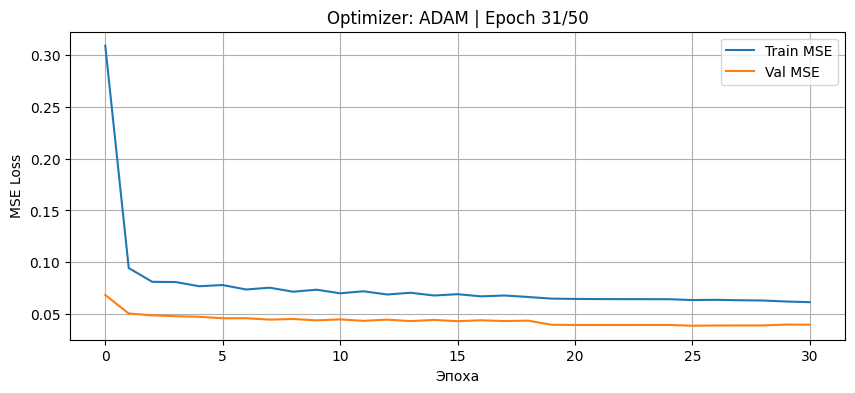

Эпоха 31/50 | Train Loss: 0.0615 | Val Loss: 0.0397
Ранняя остановка сработала на эпохе 31


In [23]:
train_losses_2l, val_losses_2l = train_and_evaluate(
    model_rnn, train_loader, val_loader, optimizer_type='adam', lr=0.001
)

=== Метрики качества: RNN ===
MSE : 5.4526
MAE : 1.9084 °C
R²  : 0.9602


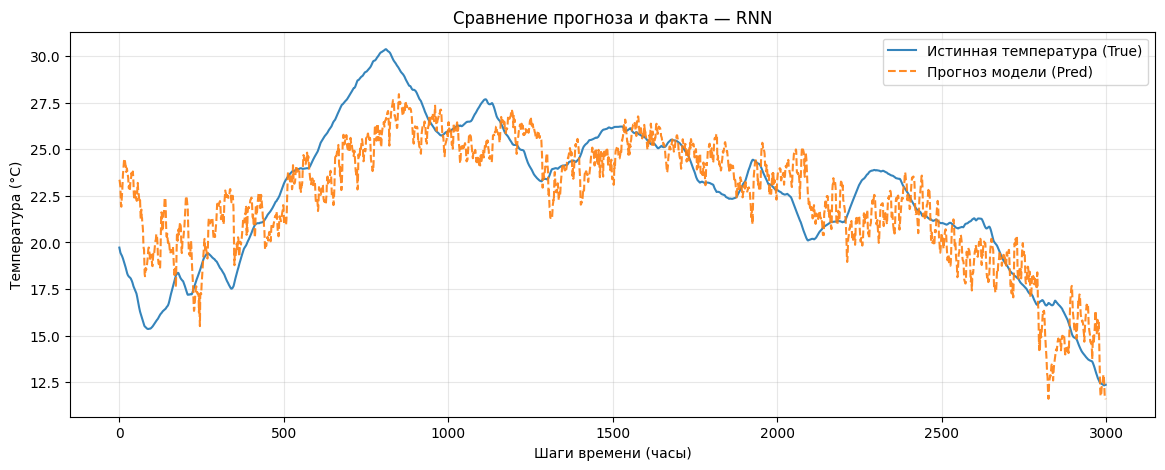

In [24]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model_rnn,       # любая ваша модель (MLP или RNN)
    data_loader=val_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="RNN",
    limit=3000
)

RNN уже заметно лучше, буду пробовать грю

In [25]:
import torch
import torch.nn as nn

class SimpleGRUWeatherModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=1, dropout=0.2):
        super(SimpleGRUWeatherModel, self).__init__()

        # Рекуррентный слой GRU
        # batch_first=True означает, что размерность батча идет первой: [Batch, Seq_Len, Features]
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # Полносвязный слой для проецирования скрытого состояния в одно число (температуру)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x имеет форму: [Batch, Seq_Len, Features]

        # out: [Batch, Seq_Len, hidden_dim] — выходы со всех шагов последовательности
        # h_n: [num_layers, Batch, hidden_dim] — последнее скрытое состояние
        out, h_n = self.gru(x)

        # Берем скрытое состояние только с самого последнего временного шага последовательности
        # h_n[-1] имеет форму: [Batch, hidden_dim]
        last_hidden = h_n[-1]

        # Прогоняем через линейный слой -> [Batch, 1]
        prediction = self.fc(last_hidden)

        return prediction

# Инициализация модели (input_dim — количество признаков в вашем DataFrame)
set_seed(42)
input_dim = X_train.shape[2]  # Для 3D тензора признаков [Batch, Len, Features]
model_gru = SimpleGRUWeatherModel(input_dim=input_dim, hidden_dim=64, num_layers=1)

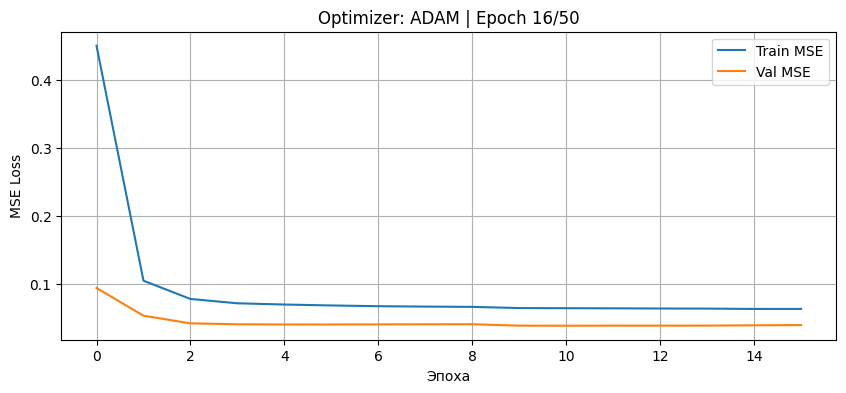

Эпоха 16/50 | Train Loss: 0.0635 | Val Loss: 0.0398
Ранняя остановка сработала на эпохе 16


In [26]:
train_losses_2l, val_losses_2l = train_and_evaluate(
    model_gru, train_loader, val_loader, optimizer_type='adam', lr=0.001
)

=== Метрики качества: GRU ===
MSE : 5.4707
MAE : 1.9061 °C
R²  : 0.9601


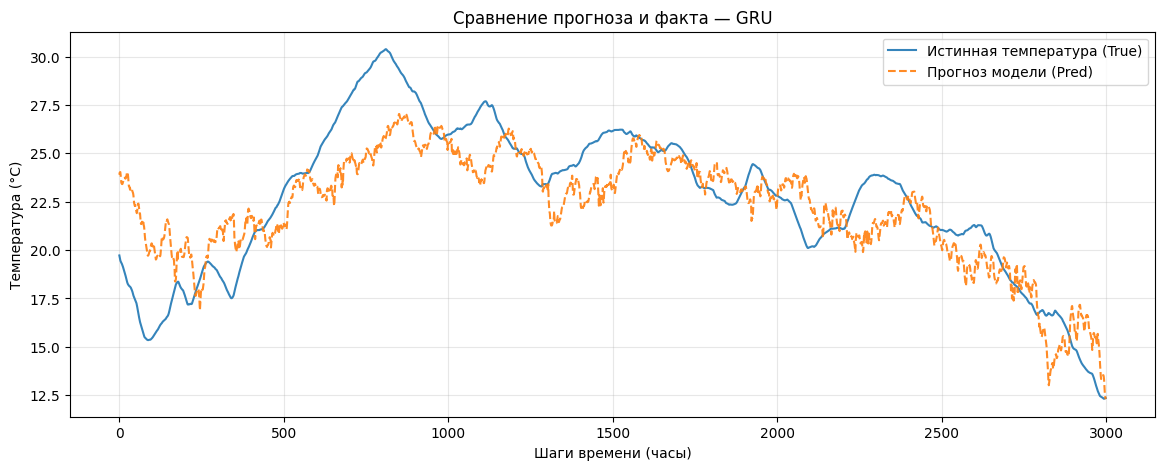

In [27]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model_gru,       # любая ваша модель (MLP или RNN)
    data_loader=val_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="GRU",
    limit=3000
)

Немного получше в плане резкости скачков

А если увеличить количество дней до 14

In [28]:
X_train, X_val, X_test, y_train, y_val, y_test, scaler_x, scaler_y = prepare_rnn_data(data, L_days=14)

# Создаем датасеты
train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

# Создаем батчи (формат батча X будет [Batch_Size, 168, Num_Features])
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=False) # Для RNN обычно shuffle=False или True, но для временных рядов без перемешивания безопаснее
val_loader = DataLoader(val_dataset, batch_size=1024, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

In [29]:
# Инициализация модели (input_dim — количество признаков в вашем DataFrame)
set_seed(42)
input_dim = X_train.shape[2]  # Для 3D тензора признаков [Batch, Len, Features]
model_gru = SimpleGRUWeatherModel(input_dim=input_dim, hidden_dim=64, num_layers=1)

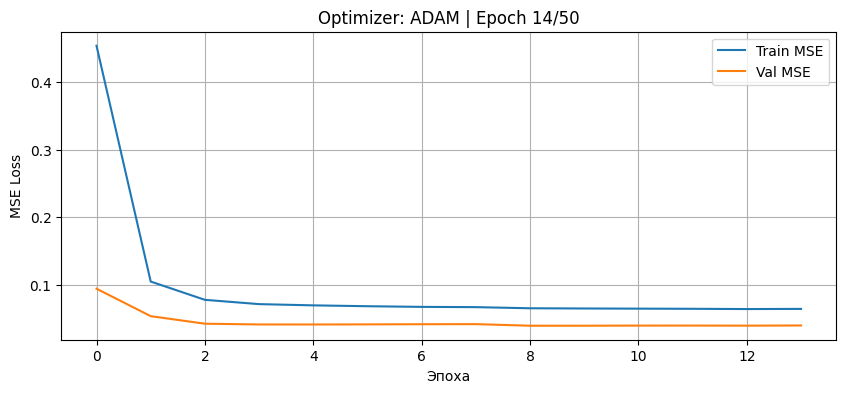

Эпоха 14/50 | Train Loss: 0.0642 | Val Loss: 0.0397
Ранняя остановка сработала на эпохе 14


In [30]:
train_losses_2l, val_losses_2l = train_and_evaluate(
    model_gru, train_loader, val_loader, optimizer_type='adam', lr=0.001
)

=== Метрики качества: GRU (14 дней) ===
MSE : 5.4466
MAE : 1.9000 °C
R²  : 0.9603


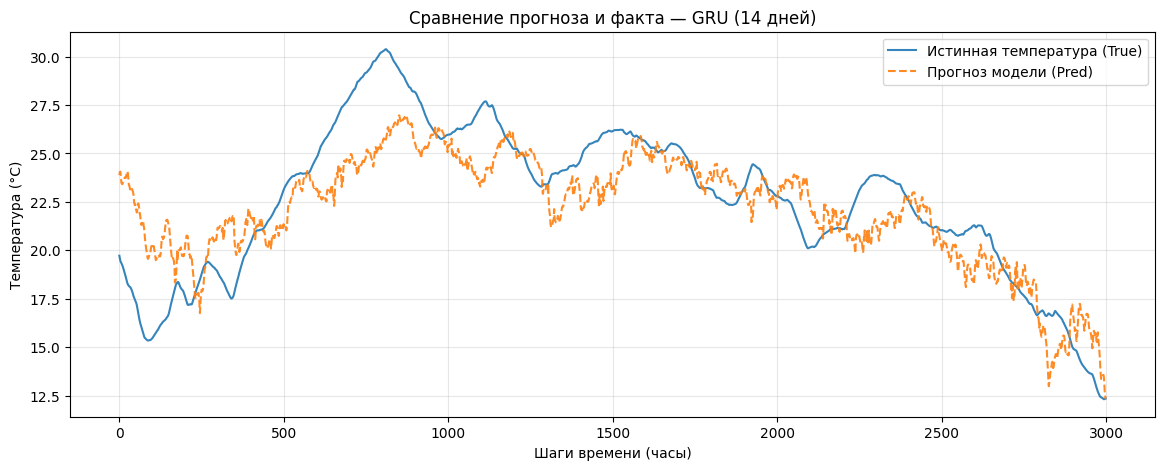

In [31]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model_gru,       # любая ваша модель (MLP или RNN)
    data_loader=val_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="GRU (14 дней)",
    limit=3000
)

Все равно не очень

Добавлю второй слой

In [32]:
import torch
import torch.nn as nn

class TwoLayerGRUWeatherModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.2):
        super(TwoLayerGRUWeatherModel, self).__init__()

        # Двухслойный рекуррентный слой GRU с дропаутом между слоями
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # Полносвязный слой для финального прогноза
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x: [Batch, Seq_Len, Features]
        out, h_n = self.gru(x)

        # h_n имеет размерность [num_layers, Batch, hidden_dim]
        # Нам нужно скрытое состояние последнего слоя
        last_hidden = h_n[-1]

        # Прогноз температуры
        prediction = self.fc(last_hidden)
        return prediction

# Инициализация модели
set_seed(42)
input_dim = X_train.shape[2]
model_gru_2l = TwoLayerGRUWeatherModel(input_dim=input_dim, hidden_dim=64, num_layers=2, dropout=0.2)

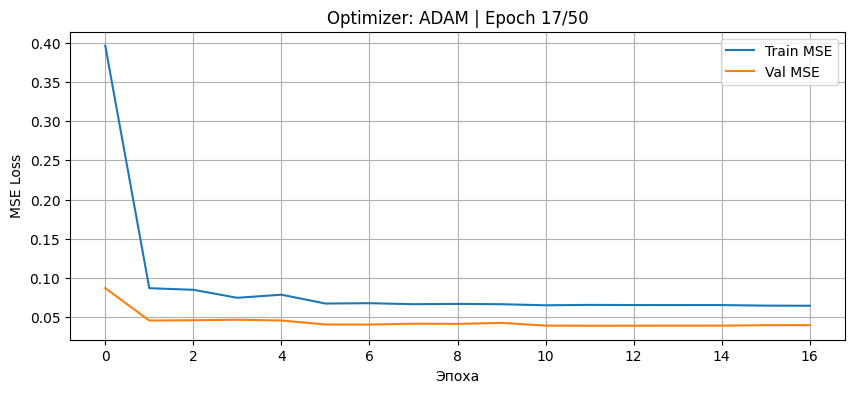

Эпоха 17/50 | Train Loss: 0.0647 | Val Loss: 0.0400
Ранняя остановка сработала на эпохе 17


In [33]:
train_losses_2l, val_losses_2l = train_and_evaluate(
    model_gru_2l, train_loader, val_loader, optimizer_type='adam', lr=0.001
)

=== Метрики качества: 2L GRU (14 дней) ===
MSE : 5.4964
MAE : 1.9024 °C
R²  : 0.9599


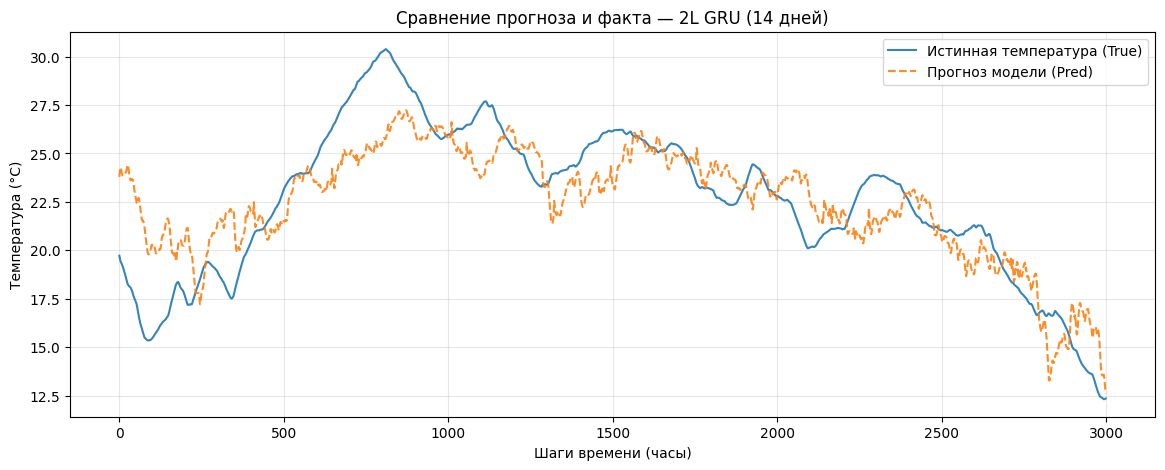

In [34]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model_gru_2l,       # любая ваша модель (MLP или RNN)
    data_loader=val_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="2L GRU (14 дней)",
    limit=3000
)

Метрики просели. Построю теперь график обычной грю на тесте для сравнения с бейзлайном

=== Метрики качества: GRU на тесте ===
MSE : 8.7379
MAE : 2.4115 °C
R²  : 0.9108


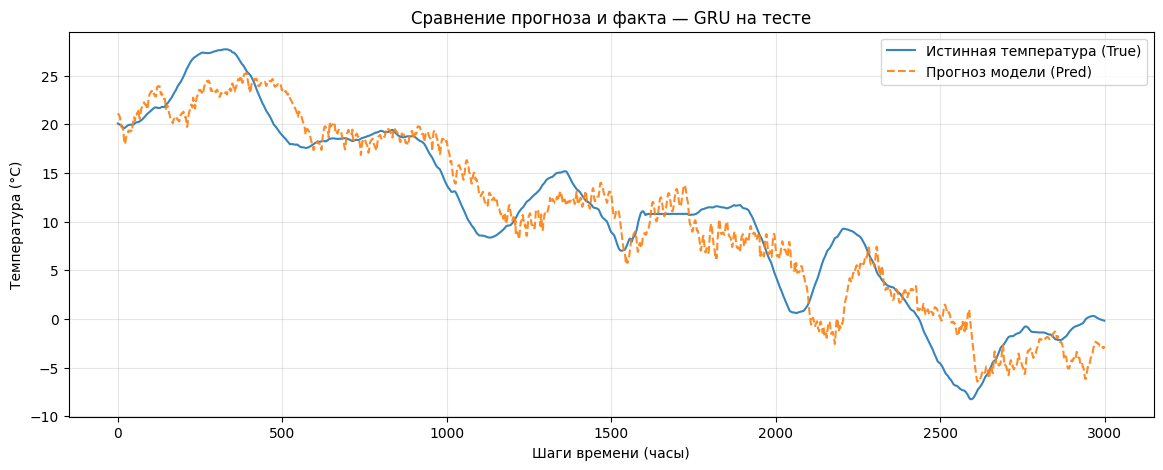

In [35]:
mse_val, mae_val, r2_val, preds, trues = evaluate_and_plot_model(
    model=model_gru,       # любая ваша модель (MLP или RNN)
    data_loader=test_loader,    # val_loader или test_loader
    scaler_y=scaler_y,         # сохраненный скалер целевой переменной
    title="GRU на тесте",
    limit=3000
)

Оно оказалось не сильно лучше бейзлайна но прогресс все же есть